# 02 — Acceptance-rate analysis

All numbers in this notebook are **loaded from the saved benchmark files** produced by
`scripts/benchmark.py` on the dev machine (2× Intel Xeon @ 2.5 GHz, 1 GiB RAM, CPU,
bf16, target `gpt2`, draft `distilgpt2`, 12 prompts × 2–3 reps, greedy unless stated):

| file | contents |
|---|---|
| `expA_greedy.json` | baseline + speculative K=4, greedy |
| `expA_sampling.json` | baseline + speculative K=4, T=0.8 / top-p 0.95 |
| `expB_K_sweep_part1/2.json` | speculative K = 2, 4, 6, 8, 12, greedy |

Questions answered here: how acceptance changes with K, how many tokens each
verification round actually yields, whether greedy vs sampling matters, and whether
workload type matters.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# find the repo root no matter where the kernel was started
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

RESULTS = ROOT / "benchmarks" / "results"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def load_records(*names):
    """Load benchmark records produced by scripts/benchmark.py."""
    recs = []
    for name in names:
        with open(RESULTS / (name + ".json")) as f:
            recs.extend(json.load(f)["records"])
    return pd.DataFrame(recs)

def save_fig(fig, filename):
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight")
    print("saved reports/figures/" + filename)


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


In [2]:
expA_g = load_records("expA_greedy")
expA_s = load_records("expA_sampling")
expB = load_records("expB_K_sweep_part1", "expB_K_sweep_part2")
print(f"expA_greedy:   {len(expA_g)} records | modes {sorted(expA_g['mode'].unique())}")
print(f"expA_sampling: {len(expA_s)} records")
print(f"expB K sweep:  {len(expB)} records | K values {sorted(expB['K'].unique())}")
expA_g.head(3)

expA_greedy:   72 records | modes ['baseline', 'speculative']
expA_sampling: 72 records
expB K sweep:  120 records | K values [np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(12)]


,mode,draft_model,target_model,device,dtype,prompt_id,category,prompt,prompt_tokens,new_tokens,...,proposed,accepted,acceptance_rate,accepted_per_iter,target_forwards,draft_forwards,target_forward_tokens,mean_tokens_per_target_forward,peak_memory_mb,cuda_peak_memory_mb
0,baseline,NaN,gpt2,cpu,bfloat16,qa-seasons,qa,Question: What causes the seasons on Earth?\nA...,12,64,...,0,0,NaN,[],64,0,75,1.0,654.9,None
1,baseline,NaN,gpt2,cpu,bfloat16,qa-seasons,qa,Question: What causes the seasons on Earth?\nA...,12,64,...,0,0,NaN,[],64,0,75,1.0,654.9,None
2,baseline,NaN,gpt2,cpu,bfloat16,qa-seasons,qa,Question: What causes the seasons on Earth?\nA...,12,64,...,0,0,NaN,[],64,0,75,1.0,654.9,None


## Greedy vs sampling acceptance

The two modes measure different quantities:

- **greedy** acceptance = how often the draft's argmax equals the target's argmax;
- **sampling** acceptance = `E_{x~q}[min(1, p(x)/q(x))] = 1 - TV(p, q)`, the total
  overlap of the two (temperature/top-p-shaped) distributions.

There is no universal ordering between them: a pair of models can agree at the argmax
yet have quite different probability mass (low sampling acceptance), or vice versa.
Which direction we measure here is an empirical question.

saved reports/figures/fig02_greedy_vs_sampling.png

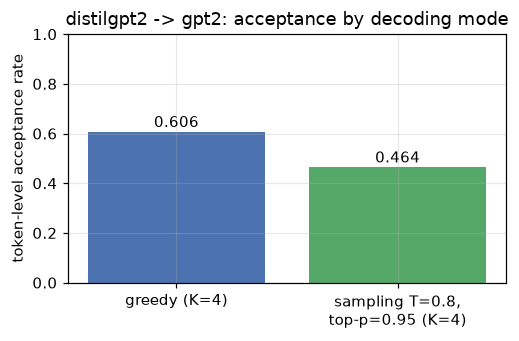

greedy   acceptance: 0.606  (argmax agreement)
sampling acceptance: 0.464  (1 - TV(p,q) under T=0.8 / top-p=0.95)

On this pair the sampling rate is LOWER than argmax agreement: distilgpt2 usually
picks the same mode as gpt2, but the full-distribution overlap 1-TV(p,q) is smaller.
This direction is a measurement, not a law - flatter distributions can also raise
acceptance for other model pairs.


In [3]:
def pooled_acceptance(df):
    spec = df[df["mode"] == "speculative"]
    return spec["accepted"].sum() / spec["proposed"].sum()

acc_greedy = pooled_acceptance(expA_g)
acc_sampling = pooled_acceptance(expA_s)

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.bar(["greedy (K=4)", "sampling T=0.8,\ntop-p=0.95 (K=4)"],
       [acc_greedy, acc_sampling], color=["#4c72b0", "#55a868"])
ax.set_ylabel("token-level acceptance rate")
ax.set_ylim(0, 1)
for i, v in enumerate([acc_greedy, acc_sampling]):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center")
ax.set_title("distilgpt2 -> gpt2: acceptance by decoding mode")
fig.tight_layout()
save_fig(fig, "fig02_greedy_vs_sampling.png")
plt.show()

print(f"greedy   acceptance: {acc_greedy:.3f}  (argmax agreement)")
print(f"sampling acceptance: {acc_sampling:.3f}  (1 - TV(p,q) under T=0.8 / top-p=0.95)")
print()
print("On this pair the sampling rate is LOWER than argmax agreement: distilgpt2 usually")
print("picks the same mode as gpt2, but the full-distribution overlap 1-TV(p,q) is smaller.")
print("This direction is a measurement, not a law - flatter distributions can also raise")
print("acceptance for other model pairs.")

## Acceptance vs draft length K

Token-level acceptance must fall with K: position *j* can only be accepted if positions
1…*j* were all accepted, so under a simple context-independent model with per-token
agreement α, the expected accepted count per round is Σ<sub>j=1..K</sub> α<sup>j</sup>,
and the token-level rate is that divided by K. We fit the single parameter α to the
measured K sweep.

fitted per-token agreement alpha = 0.80
measured: {2: np.float64(0.747), 4: np.float64(0.606), 6: np.float64(0.45), 8: np.float64(0.424), 12: np.float64(0.347)}


saved reports/figures/fig02_acceptance_vs_k.png


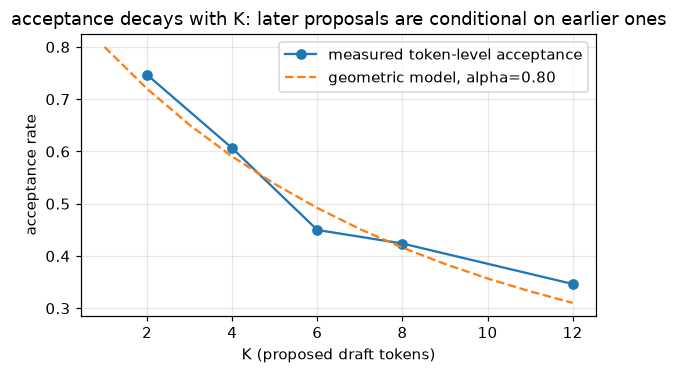

In [4]:
ks = sorted(expB["K"].unique())
acc_by_k = {int(k): expB[expB["K"] == k]["accepted"].sum() / expB[expB["K"] == k]["proposed"].sum()
            for k in ks}

def model_token_acc(alpha, K):
    return sum(alpha ** j for j in range(1, K + 1)) / K

grid = np.arange(0.30, 0.96, 0.01)
sse = {a: sum((model_token_acc(a, k) - acc_by_k[k]) ** 2 for k in ks) for a in grid}
best_alpha = min(sse, key=sse.get)
print(f"fitted per-token agreement alpha = {best_alpha:.2f}")
print("measured:", {k: round(v, 3) for k, v in acc_by_k.items()})

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(ks, [acc_by_k[int(k)] for k in ks], "o-", label="measured token-level acceptance")
kk = np.arange(1, 13)
ax.plot(kk, [model_token_acc(best_alpha, k) for k in kk], "--",
        label=f"geometric model, alpha={best_alpha:.2f}")
ax.set_xlabel("K (proposed draft tokens)")
ax.set_ylabel("acceptance rate")
ax.set_title("acceptance decays with K: later proposals are conditional on earlier ones")
ax.legend()
fig.tight_layout()
save_fig(fig, "fig02_acceptance_vs_k.png")
plt.show()

## How many tokens does a verification round actually yield?

Each round commits `accepted + 1` tokens (the +1 is the replacement or bonus token sampled from the target). The histograms below are built from the per-round accepted counts stored in every record (`accepted_per_iter`).

saved reports/figures/fig02_accepted_per_iter.png


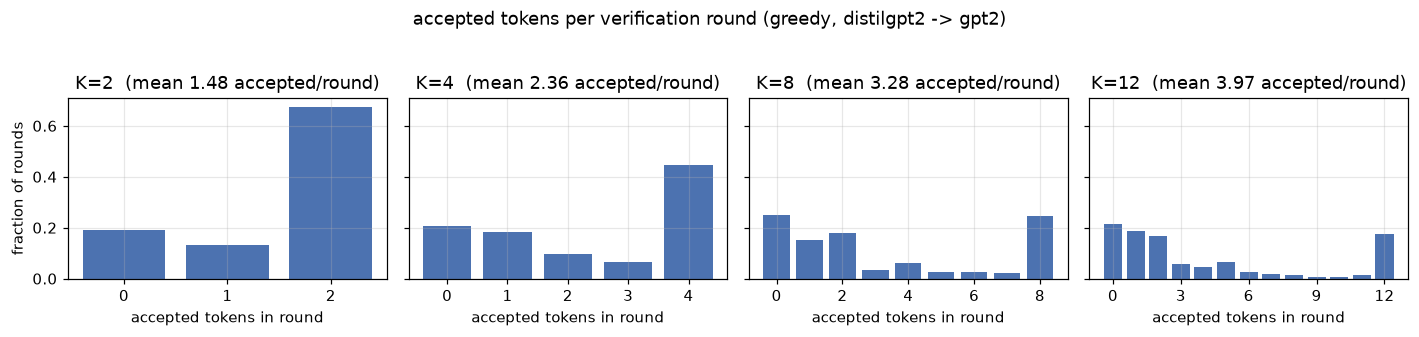

K= 2: P(all accepted) = 0.675 | P(none accepted) = 0.192
K= 4: P(all accepted) = 0.447 | P(none accepted) = 0.206
K= 8: P(all accepted) = 0.246 | P(none accepted) = 0.251
K=12: P(all accepted) = 0.175 | P(none accepted) = 0.214


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9), sharey=True)
for ax, K in zip(axes, [2, 4, 8, 12]):
    per_iter = np.concatenate(expB.loc[expB["K"] == K, "accepted_per_iter"].tolist())
    counts = np.bincount(per_iter, minlength=K + 1)[: K + 1]
    ax.bar(np.arange(K + 1), counts / counts.sum(), color="#4c72b0")
    ax.set_title(f"K={K}  (mean {per_iter.mean():.2f} accepted/round)")
    ax.set_xlabel("accepted tokens in round")
    ax.set_xticks(np.arange(0, K + 1, max(1, K // 4)))
axes[0].set_ylabel("fraction of rounds")
fig.suptitle("accepted tokens per verification round (greedy, distilgpt2 -> gpt2)", y=1.04)
fig.tight_layout()
save_fig(fig, "fig02_accepted_per_iter.png")
plt.show()

for K in [2, 4, 8, 12]:
    per_iter = np.concatenate(expB.loc[expB["K"] == K, "accepted_per_iter"].tolist())
    print(f"K={K:2d}: P(all accepted) = {(per_iter == K).mean():.3f} | "
          f"P(none accepted) = {(per_iter == 0).mean():.3f}")

## Acceptance by workload (greedy, K=4)

Experiment D signal: the same draft/target pair agrees very differently depending on what it is asked to generate.

saved reports/figures/fig02_acceptance_by_category.png


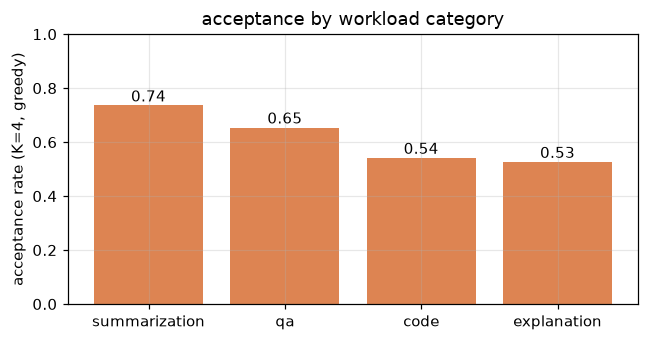

per-prompt acceptance:
  qa-seasons               0.701
  qa-photosynthesis        0.600
  qa-history               0.667
  code-fibonacci           0.648
  code-reverse             0.537
  code-class               0.461
  sum-industrial           0.787
  sum-story                0.860
  sum-science              0.600
  expl-neural-net          0.557
  expl-gravity             0.667
  expl-compound-interest   0.402


In [6]:
spec_g = expA_g[expA_g["mode"] == "speculative"]
cats = sorted(spec_g["category"].unique())
acc_by_cat = {c: spec_g[spec_g["category"] == c]["accepted"].sum()
                 / spec_g[spec_g["category"] == c]["proposed"].sum() for c in cats}
order = sorted(acc_by_cat, key=acc_by_cat.get, reverse=True)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(order, [acc_by_cat[c] for c in order], color="#dd8452")
ax.set_ylabel("acceptance rate (K=4, greedy)")
ax.set_title("acceptance by workload category")
ax.set_ylim(0, 1)
for i, c in enumerate(order):
    ax.text(i, acc_by_cat[c] + 0.015, f"{acc_by_cat[c]:.2f}", ha="center")
fig.tight_layout()
save_fig(fig, "fig02_acceptance_by_category.png")
plt.show()

print("per-prompt acceptance:")
for pid in spec_g["prompt_id"].unique():
    d = spec_g[spec_g["prompt_id"] == pid]
    print(f"  {pid:24s} {d['accepted'].sum() / d['proposed'].sum():.3f}")

## Findings (all computed above)

1. **Acceptance falls with K** roughly geometrically; the fitted per-token agreement
   α (printed above) summarizes the draft/target pair in one number. Measured
   token-level acceptance drops from ~0.75 at K=2 to ~0.35 at K=12.
2. **Full-accept rounds become rare as K grows** — large K mostly buys wasted draft
   work on this pair (see P(all accepted)).
3. **Sampling acceptance ≠ greedy acceptance**: here T=0.8/top-p sampling gives a
   *lower* rate (1−TV) than argmax agreement. "Acceptance rate" always needs the
   decoding mode attached to it.
4. **Workload matters**: summarization-style prompts (continuations constrained by a
   provided passage) reach the highest agreement; open-ended explanations the lowest.
   Notebook 05 connects this to throughput.